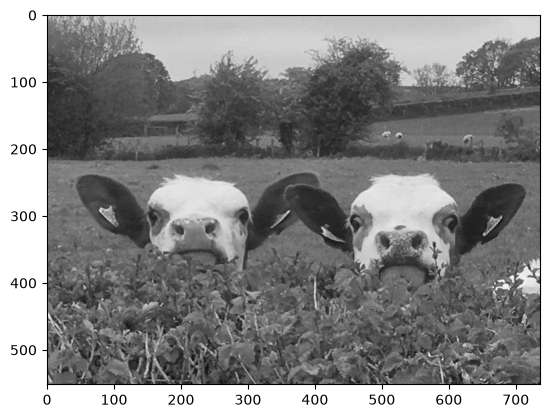

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

image = cv2.imread('img_2.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")
plt.show()


== noise_gauss ==
[[  0  16   0 ...   0  32   5]
 [ 46  83 118 ...  40   0 100]
 [149  60   0 ... 242   0   0]
 ...
 [  0   0  19 ...   0   0  26]
 [  0   0  96 ...   0   0  30]
 [178   0  83 ...   0 124 208]]


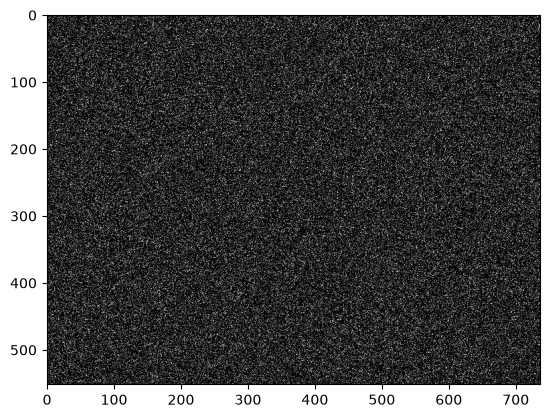

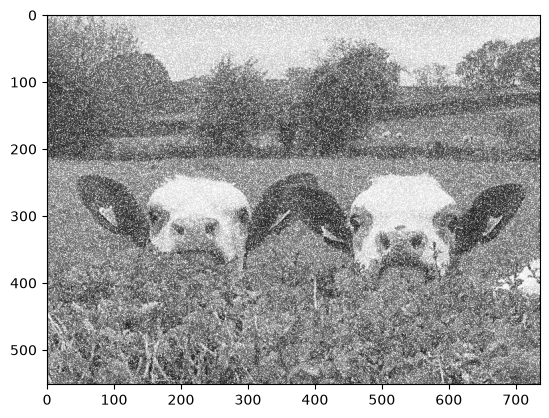

In [2]:
# Зашумление изображения при помощи шума гаусса, постоянного шума.
# Шум гаусса
mean = 0
stddev = 100
noise_gauss = np.zeros(image_gray.shape, np.uint8)
cv2.randn(noise_gauss, mean, stddev)
print('== noise_gauss ==')
print(noise_gauss)

plt.imshow(noise_gauss, cmap="gray")
plt.show()

image_noise_gauss = cv2.add(image_gray,noise_gauss)
plt.imshow(image_noise_gauss, cmap="gray")
plt.show()

== noise_uniform ==
[[21.79586    22.019876   14.831402   ...  3.674326   31.592745
  30.322819  ]
 [24.708374   35.657146   23.76655    ... 12.991791    1.8725033
  40.61252   ]
 [10.175997   49.034676    0.16917229 ... 48.41503    48.70774
  40.79992   ]
 ...
 [25.03264    10.172123   35.02799    ... 28.27956    10.615368
  49.04509   ]
 [27.233948   44.518143    7.2240696  ... 24.828018   11.684317
  47.603493  ]
 [ 7.7207355  39.959736   30.40356    ... 10.715774   17.633936
  37.99639   ]]


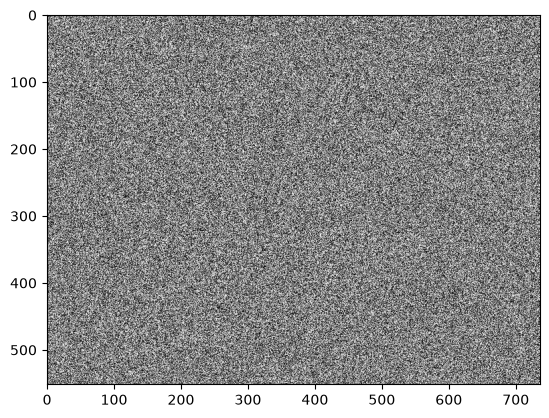

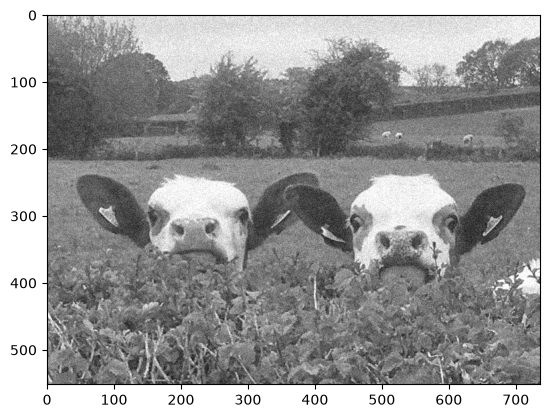

In [3]:
# Постоянный шум
noise_uniform = np.zeros(image_gray.shape, np.float32)
a = 0
b = 50
cv2.randu(noise_uniform, a, b)
print('== noise_uniform ==')
print(noise_uniform)

plt.imshow(noise_uniform, cmap="gray")
plt.show()  

image_noise_uniform = cv2.add(image_gray.astype(np.float32), noise_uniform)
image_noise_uniform = np.clip(image_noise_uniform, 0, 255).astype(np.uint8)
plt.imshow(image_noise_uniform, cmap="gray")
plt.show()

== Шум гаусса: ==
-- до --
3496.174493935098 0.1580450827656321
-- Медианный фильтр --
MSE: 878.6525332781979
SSIM: 0.3855934179262505


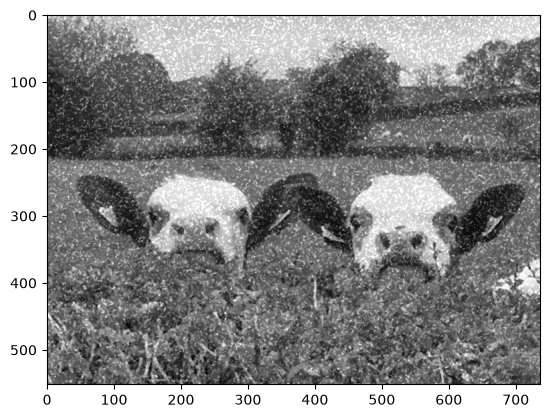

-- Фильтр Гаусса --
MSE: 1446.9066019809388
SSIM: 0.533426701574267


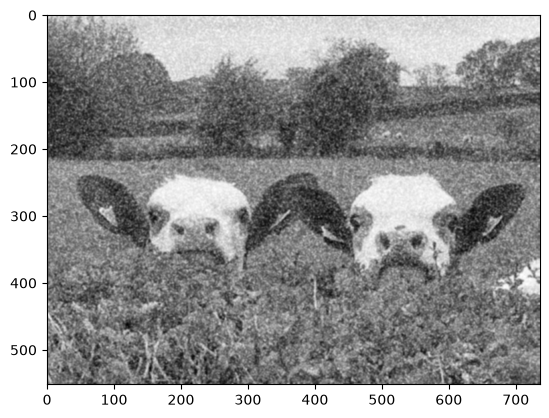

-- Билатеральный фильтр --
MSE: 1472.9572158553876
SSIM: 0.3752087164405406


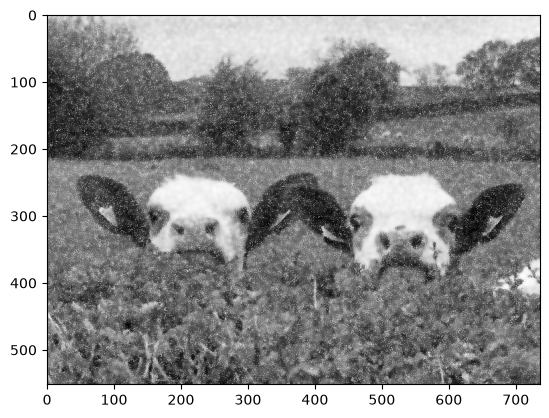

-- Фильтр нелокальных средних --
MSE: 3415.5002289106806
SSIM: 0.25257790498047505


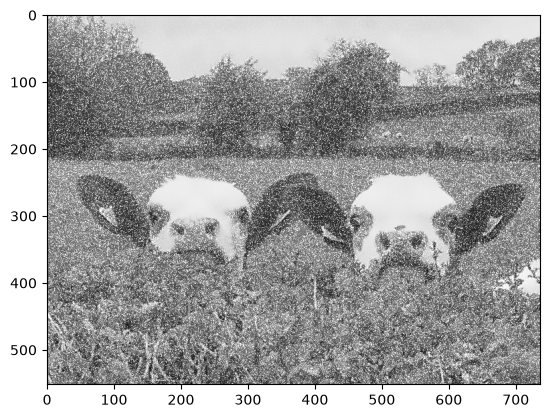

Лучший по MSE: Медианный
Лучший по SSIM: Гаусса


In [4]:
# Протестировать медианный фильтр, фильтр гаусса, билатериальный фильтр, фильтр нелокальных средних с различными параметрами.
# Шум гаусса:
print('== Шум гаусса: ==')
from skimage.metrics import structural_similarity, mean_squared_error
mse_gauss = mean_squared_error(image_gray, image_noise_gauss)
(ssim, diff) = structural_similarity(image_gray, image_noise_gauss, full=True)
print('-- до --')
print(mse_gauss, ssim)

print('-- Медианный фильтр --')
image_gauss_median = cv2.medianBlur(image_noise_gauss, 3)

mse_gauss_median = mean_squared_error(image_gray, image_gauss_median)
(ssim_gauss_median, diff) = structural_similarity(image_gray,  image_gauss_median, full=True)

print('MSE:', mse_gauss_median)
print('SSIM:', ssim_gauss_median)
plt.imshow(image_gauss_median, cmap="gray")
plt.show()


print('-- Фильтр Гаусса --')
image_gauss_gaussian = cv2.GaussianBlur(image_noise_gauss, (5, 5), 0)

mse_gauss_gaussian = mean_squared_error(image_gray, image_gauss_gaussian)
ssim_gauss_gaussian, diff = structural_similarity(image_gray, image_gauss_gaussian, full=True)

print('MSE:', mse_gauss_gaussian)
print('SSIM:', ssim_gauss_gaussian)
plt.imshow(image_gauss_gaussian, cmap="gray")
plt.show()


print('-- Билатеральный фильтр --')
image_gauss_bilateral = cv2.bilateralFilter(image_noise_gauss,9,75,75)

mse_gauss_bilateral = mean_squared_error(image_gray, image_gauss_bilateral)
ssim_gauss_bilateral, diff = structural_similarity(image_gray, image_gauss_bilateral, full=True)

print('MSE:', mse_gauss_bilateral)
print('SSIM:', ssim_gauss_bilateral)
plt.imshow(image_gauss_bilateral, cmap="gray")
plt.show()


print('-- Фильтр нелокальных средних --')
image_gauss_nlm = cv2.fastNlMeansDenoising(image_noise_gauss,h = 20)

mse_gauss_nlm = mean_squared_error(image_gray, image_gauss_nlm)
ssim_gauss_nlm, diff = structural_similarity(image_gray, image_gauss_nlm, full=True)

print('MSE:', mse_gauss_nlm)
print('SSIM:', ssim_gauss_nlm)
plt.imshow(image_gauss_nlm, cmap="gray")
plt.show()

def best_filter():
    mse = {
        'Медианный': mse_gauss_median,
        'Гаусса': mse_gauss_gaussian,
        'Билатеральный': mse_gauss_bilateral,
        'Нелокальных средних': mse_gauss_nlm
    }

    ssim = {
        'Медианный': ssim_gauss_median,
        'Гаусса': ssim_gauss_gaussian,
        'Билатеральный': ssim_gauss_bilateral,
        'Нелокальных средних': ssim_gauss_nlm
    }

    print('Лучший по MSE:', min(mse, key=mse.get))
    print('Лучший по SSIM:', max(ssim, key=ssim.get))

best_filter()

== Постоянный шум: ==
-- до --
803.1432390122874 0.5394389259709931
-- Медианный фильтр --
MSE: 680.6605574590423
SSIM: 0.7224632643221984


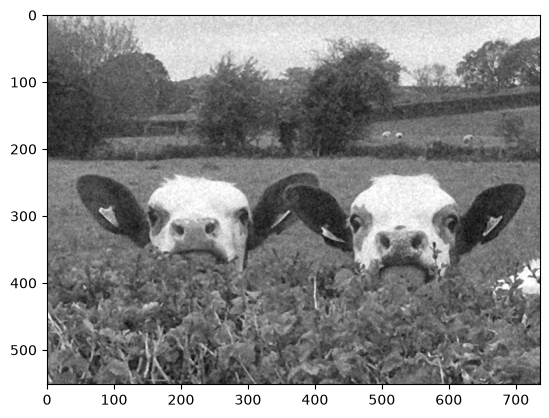

-- Фильтр Гаусса --
MSE: 656.8895149062697
SSIM: 0.8294285233885955


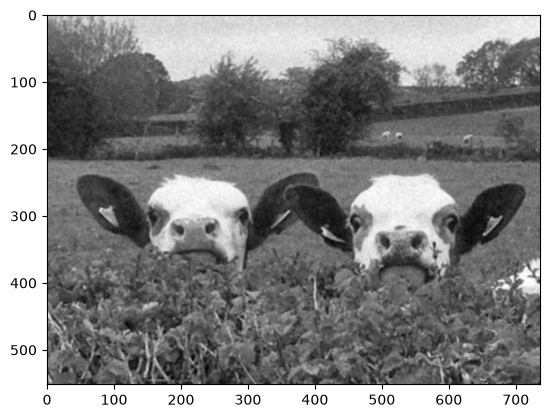

-- Билатеральный фильтр --
MSE: 710.0003322896976
SSIM: 0.7209230107878742


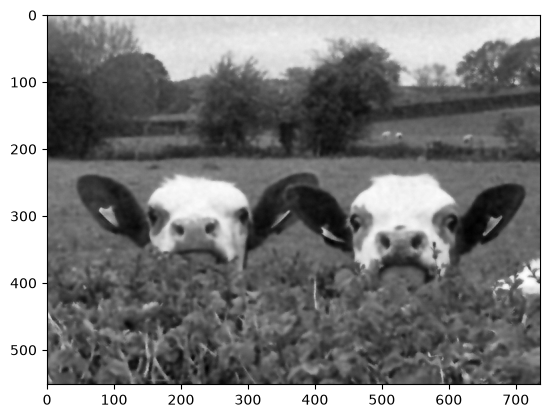

-- Фильтр нелокальных средних --
MSE: 683.8301507364524
SSIM: 0.725544206681364


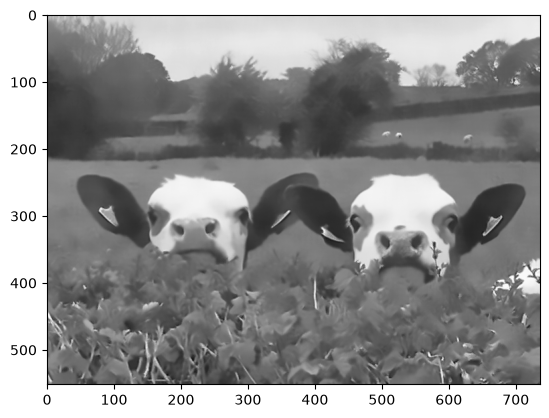

Лучший по MSE: Гаусса
Лучший по SSIM: Гаусса


In [5]:
# Постоянный шум:
print('== Постоянный шум: ==')
mse_uniform = mean_squared_error(image_gray, image_noise_uniform)
(ssim_uniform, diff) = structural_similarity(image_gray, image_noise_uniform, full=True)

print('-- до --')
print(mse_uniform, ssim_uniform)

print('-- Медианный фильтр --')
image_uniform_median = cv2.medianBlur(image_noise_uniform, 3)

mse_uniform_median = mean_squared_error(image_gray, image_uniform_median)
ssim_uniform_median, diff = structural_similarity(image_gray, image_uniform_median, full=True)

print('MSE:', mse_uniform_median)
print('SSIM:', ssim_uniform_median)

plt.imshow(image_uniform_median, cmap="gray")
plt.show()


print('-- Фильтр Гаусса --')
image_uniform_gaussian = cv2.GaussianBlur(image_noise_uniform, (5, 5), 0)

mse_uniform_gaussian = mean_squared_error(image_gray, image_uniform_gaussian)
ssim_uniform_gaussian, diff = structural_similarity(image_gray, image_uniform_gaussian, full=True)

print('MSE:', mse_uniform_gaussian)
print('SSIM:', ssim_uniform_gaussian)

plt.imshow(image_uniform_gaussian, cmap="gray")
plt.show()


print('-- Билатеральный фильтр --')
image_uniform_bilateral = cv2.bilateralFilter(image_noise_uniform, 9, 75, 75)

mse_uniform_bilateral = mean_squared_error(image_gray, image_uniform_bilateral)
ssim_uniform_bilateral, diff = structural_similarity(image_gray, image_uniform_bilateral, full=True)

print('MSE:', mse_uniform_bilateral)
print('SSIM:', ssim_uniform_bilateral)

plt.imshow(image_uniform_bilateral, cmap="gray")
plt.show()


print('-- Фильтр нелокальных средних --')
image_uniform_nlm = cv2.fastNlMeansDenoising(image_noise_uniform, h=20)

mse_uniform_nlm = mean_squared_error(image_gray, image_uniform_nlm)
ssim_uniform_nlm, diff = structural_similarity(image_gray, image_uniform_nlm, full=True)

print('MSE:', mse_uniform_nlm)
print('SSIM:', ssim_uniform_nlm)

plt.imshow(image_uniform_nlm, cmap="gray")
plt.show()

def best_filter_uniform():
    mse = {
        'Медианный': mse_uniform_median,
        'Гаусса': mse_uniform_gaussian,
        'Билатеральный': mse_uniform_bilateral,
        'Нелокальных средних': mse_uniform_nlm
    }

    ssim = {
        'Медианный': ssim_uniform_median,
        'Гаусса': ssim_uniform_gaussian,
        'Билатеральный': ssim_uniform_bilateral,
        'Нелокальных средних': ssim_uniform_nlm
    }

    print('Лучший по MSE:', min(mse, key=mse.get))
    print('Лучший по SSIM:', max(ssim, key=ssim.get))

best_filter_uniform()